Energy eigenvalues:
n = 0 : E = 0.707094
n = 1 : E = 2.121262
n = 2 : E = 3.535433
n = 3 : E = 4.950035
n = 4 : E = 6.367440
n = 5 : E = 7.796635


/tmp/ipykernel_53286/4109427068.py:18: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  H = sparse.diags([-1, 2, -1], [-1, 0, 1], shape=(Nx, Nx))/ dx**2


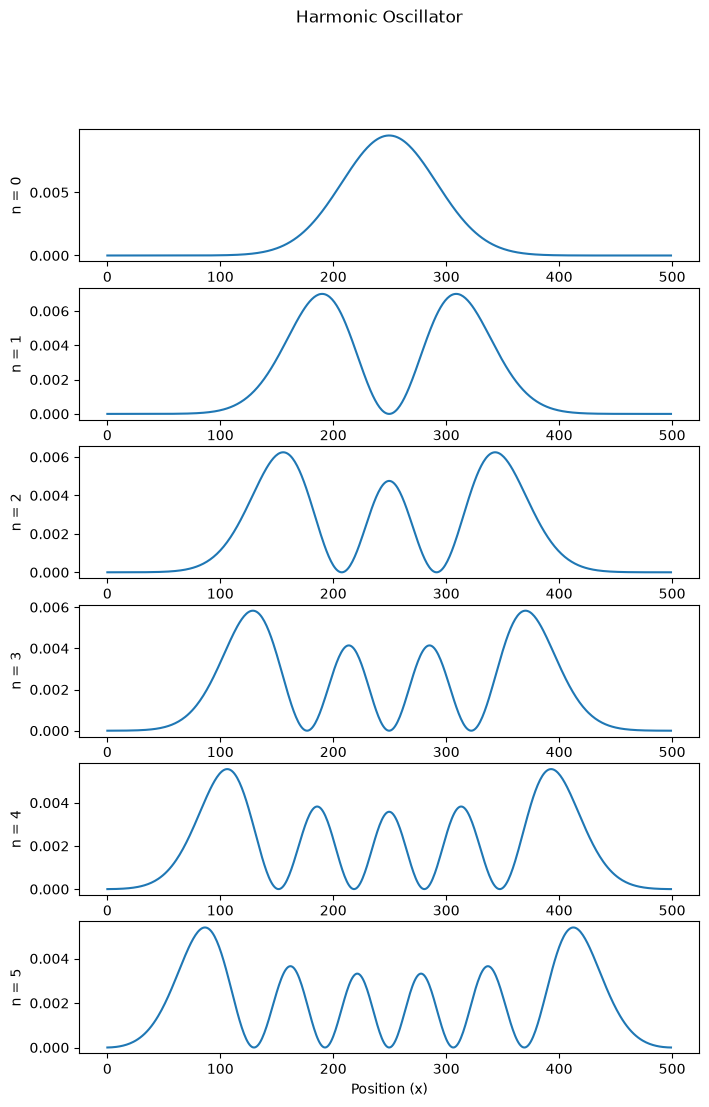

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import eigsh


def Vfun(x, k):
    return k * x**2

#2. Solve the Schrodinger equation

def schrodinger1D(xmin, xmax, Nx, k, neigs):

    x = np.linspace(xmin, xmax, Nx)
    dx= x[1] - x[0]
#Kinetic energy matrix
    H = sparse.diags([-1, 2, -1], [-1, 0, 1], shape=(Nx, Nx))/ dx**2
 #Adding potential energy
    H += sparse.diags(Vfun(x, k))

 #energy eigenvalues and eigenfunctions
    energies, wavefunctions = eigsh(H, k=neigs, which ="SA")
    indices = np.argsort(energies)

    return x, energies[indices], wavefunctions[:, indices]

#3. Example Parameters:
xmin=-5
xmax=5
Nx=500
k=0.5
neigs=6


x, energies, wavefunctions = schrodinger1D(xmin, xmax, Nx, k, neigs)

print("Energy eigenvalues:")
for n, E in enumerate(energies):
    print(f"n = {n} : E = {E:4f}")



fig, axes = plt.subplots(neigs, 1, figsize=(8,12))

for n in range(neigs):
    psi = wavefunctions[:, n]
    prob = np.abs(psi)**2

    axes[n].plot(prob)
    axes[n].set_ylabel(f"n = {n}")

axes[-1].set_xlabel("Position (x)")

plt.suptitle("Harmonic Oscillator")
plt.show()    

    
